# Validate the saved narration head
Run after training. Evaluate the complete natural validation set with the saved threshold.
No retraining or threshold search. Error examples are for auditing, not tuning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageDraw
from torch import nn

ROOT = Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi\isNarratorTextMagi')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MAX_ERRORS = 5
data = torch.load(ROOT / 'narration_data.pt', map_location='cpu', weights_only=True)
checkpoint = torch.load(ROOT / 'narration_head.pt', map_location='cpu', weights_only=True)
assert data['settings']['data_source'] == 'development'
assert data['settings'].get('split_strategy') == 'surviving_tokens_narration_and_sequence_v2', 'Regenerate the dataset with the updated split notebook.'
assert checkpoint['selection_metric'] == 'narration_f1'
assert checkpoint.get('architecture', {}).get('type') == 'mlp', 'Retrain with the updated MLP notebook.'
assert checkpoint['architecture']['activation'] == 'relu'
assert checkpoint['dataset_id'] == data['dataset_id'], 'Checkpoint belongs to another dataset.'
assert checkpoint['model_identity'] == data['model_identity']
assert checkpoint['feature_dim'] == data['feature_dim']
samples = [data['samples'][i] for i in data['splits']['validation']]
assert {s['label'] for s in samples} == {0, 1}
threshold = float(checkpoint['validation_threshold'])
print('Best epoch:', checkpoint['best_epoch'], '| Saved threshold:', threshold)


Best epoch: 11 | Saved threshold: 0.5246874690055847


In [2]:
class NarrationHead(nn.Module):
    def __init__(self, feature_dim, hidden_dim):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.classifier(x).squeeze(-1)



def classification_metrics(labels, probabilities, threshold):
    labels = np.asarray(labels, dtype=np.int64)
    predictions = np.asarray(probabilities, dtype=np.float64) >= threshold
    tp = int(((labels == 1) & predictions).sum())
    fp = int(((labels == 0) & predictions).sum())
    tn = int(((labels == 0) & ~predictions).sum())
    fn = int(((labels == 1) & ~predictions).sum())
    precision = tp / (tp + fp) if tp + fp else None
    recall = tp / (tp + fn) if tp + fn else 0.0
    negative_recall = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    f0_5 = 1.25 * tp / (1.25 * tp + fp + .25 * fn) if 1.25 * tp + fp + .25 * fn else 0.0
    return dict(tp=tp, fp=fp, tn=tn, fn=fn, narration_precision=precision,
        narration_recall=recall, narration_f1=f1, narration_f0_5=f0_5,
        non_narration_recall=negative_recall, balanced_accuracy=(recall + negative_recall) / 2,
        accuracy=(tp + tn) / len(labels), predicted_narration=tp + fp, actual_narration=tp + fn)


def selection_key(metrics):
    precision = metrics['narration_precision']
    return (metrics['narration_f1'], precision if precision is not None else -1.0,
            metrics['narration_recall'], metrics['balanced_accuracy'])


In [3]:
head = NarrationHead(checkpoint['feature_dim'], checkpoint['architecture']['hidden_dim']).to(DEVICE)
head.load_state_dict(checkpoint['state_dict'])
head.eval()
head.requires_grad_(False)
probabilities = []
with torch.no_grad():
    for start in range(0, len(samples), 64):
        features = torch.stack([s['detr_embedding'].float() for s in samples[start:start + 64]]).to(DEVICE)
        probabilities.extend(torch.sigmoid(head(features)).cpu().tolist())
probabilities = np.asarray(probabilities, dtype=np.float64)
labels = np.asarray([s['label'] for s in samples], dtype=np.int64)
predictions = probabilities >= threshold
metrics = classification_metrics(labels, probabilities, threshold)
for name, value in metrics.items():
    print(f'{name}: {value:.4f}' if isinstance(value, float) else f'{name}: {value}')
saved_counts = {name: checkpoint['validation'][name] for name in ['tp', 'fp', 'tn', 'fn']}
current_counts = {name: metrics[name] for name in saved_counts}
print('Saved confusion counts reproduced:', current_counts == saved_counts)


tp: 9
fp: 21
tn: 263
fn: 4
narration_precision: 0.3000
narration_recall: 0.6923
narration_f1: 0.4186
narration_f0_5: 0.3383
non_narration_recall: 0.9261
balanced_accuracy: 0.8092
accuracy: 0.9158
predicted_narration: 30
actual_narration: 13
Saved confusion counts reproduced: True


## Inspect a few false positives and false negatives

False positive | Total: 21


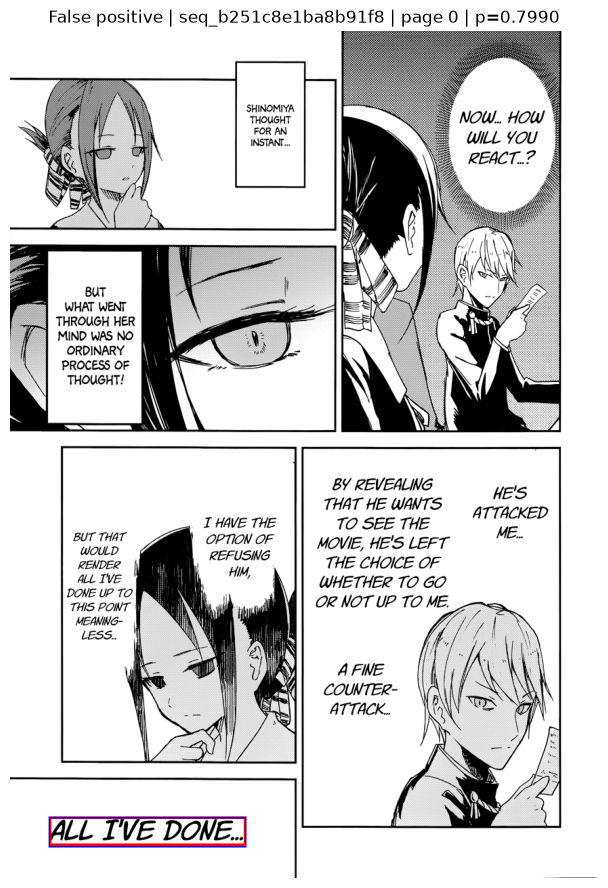

OCR: All I've done...
GT: ALL I'VE DONE...
GT speaker: character2
Query: 259 | IoU: 0.918 | Match: direct | Score: 100.0


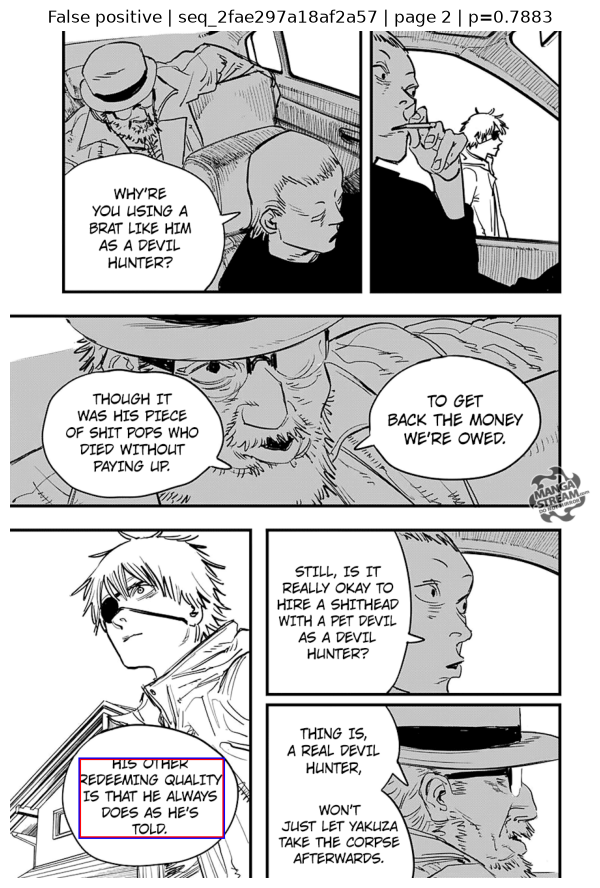

OCR: His other redeeming quality is that he always does as he's told.
GT: HIS OTHER REDEEMING QUALITY IS THAT HE ALWAYS DOES AS HE'S TOLD.
GT speaker: character2
Query: 163 | IoU: 1.0 | Match: direct | Score: 100.0


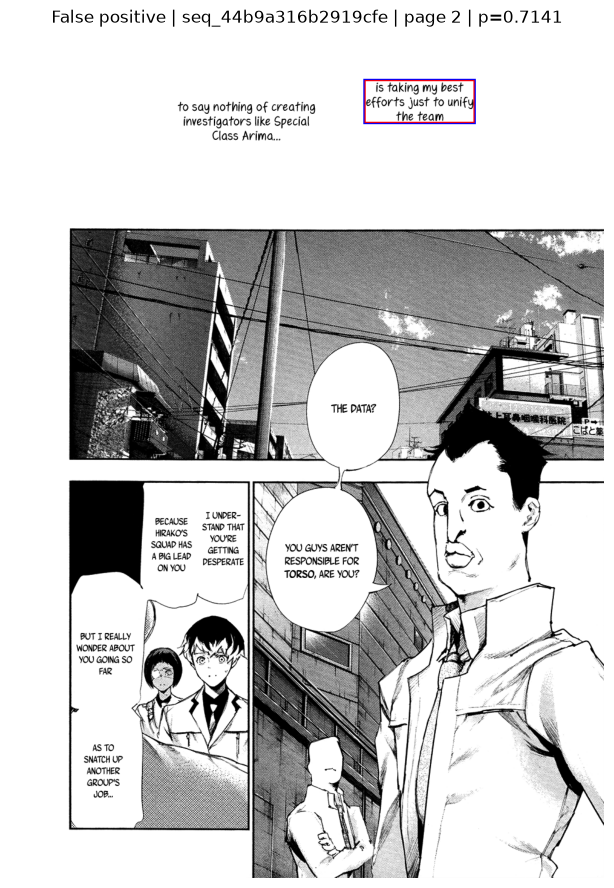

OCR: is taking my best efforts just to unify the team
GT: is taking my best efforts just to unify the team
GT speaker: character1
Query: 235 | IoU: 0.999 | Match: direct | Score: 100.0


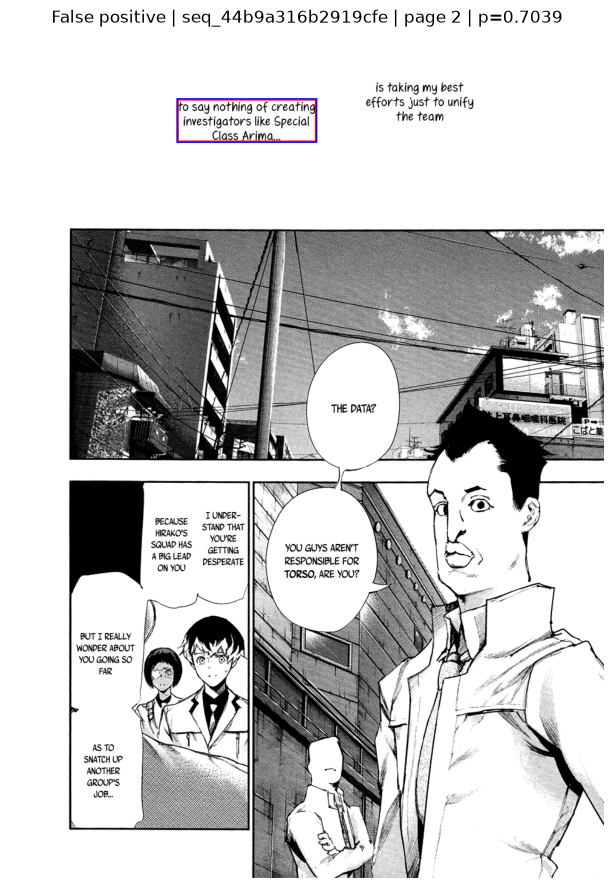

OCR: to say nothing of creating investigators like Special Class Arima...
GT: to say nothing of creating investigators like Special Class Arima...
GT speaker: character1
Query: 266 | IoU: 0.9982 | Match: direct | Score: 100.0


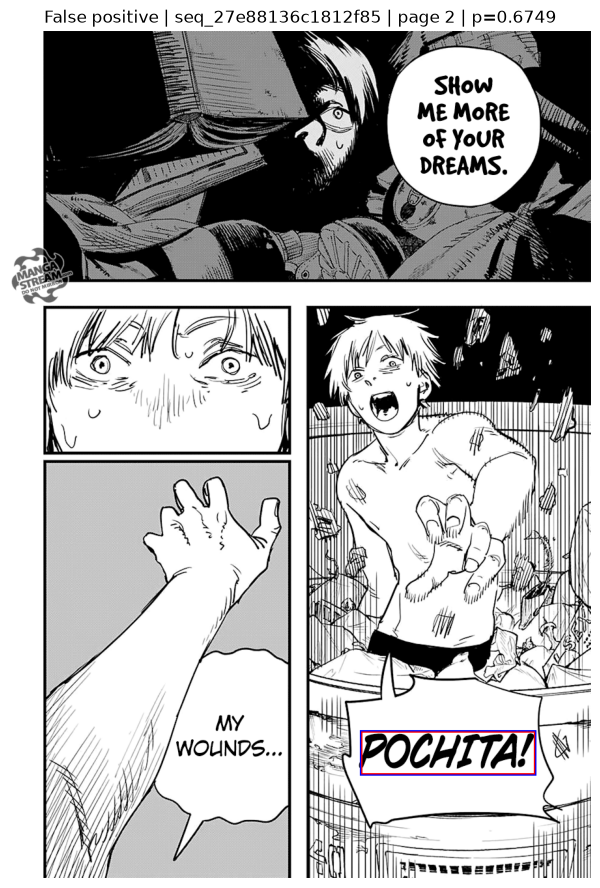

OCR: Pochita!
GT: POCHITA!
GT speaker: character1
Query: 9 | IoU: 1.0 | Match: direct | Score: 100.0
False negative | Total: 4


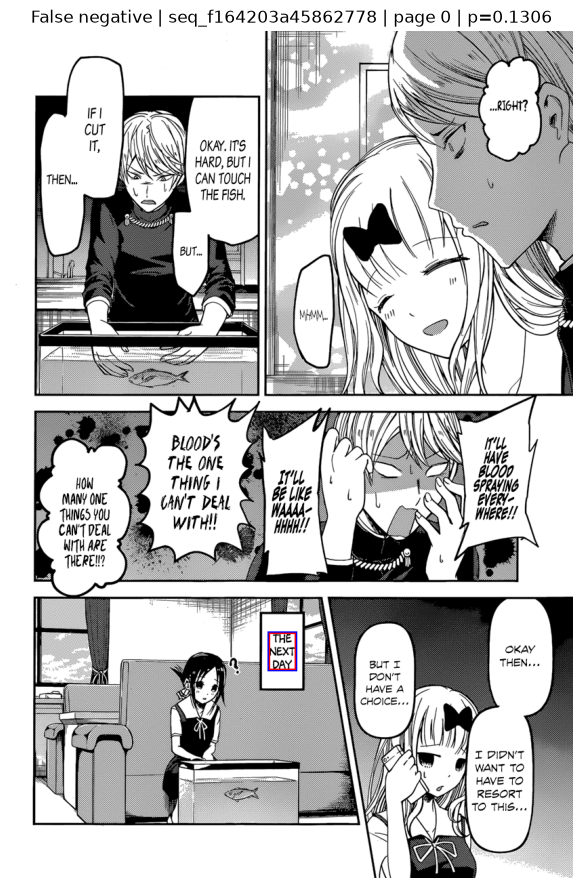

OCR: The next day
GT: THE NEXT DAY
GT speaker: NARRATION
Query: 77 | IoU: 0.9999 | Match: direct | Score: 100.0


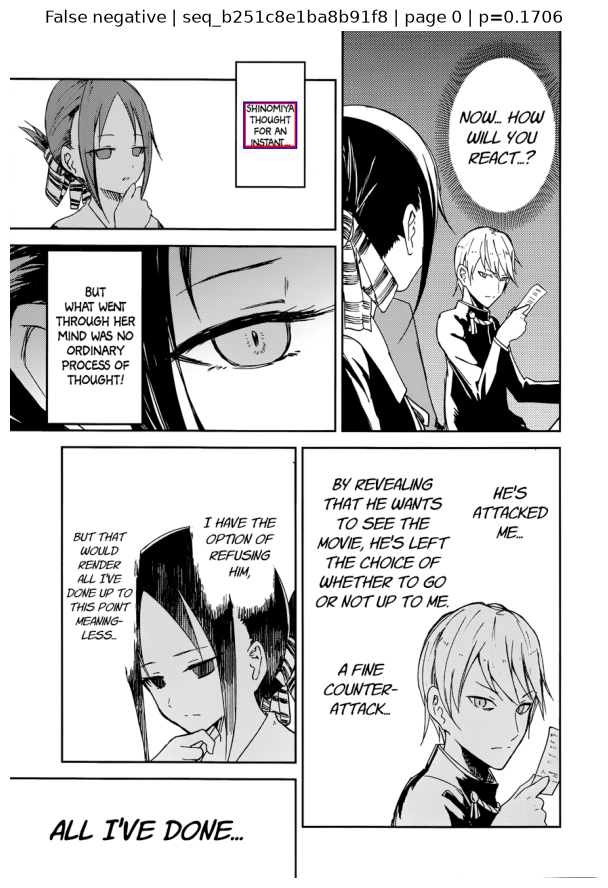

OCR: Shinomiya thought for an instant...
GT: SHINOMIYA THOUGHT FOR AN INSTANT...
GT speaker: NARRATION
Query: 7 | IoU: 0.9892 | Match: direct | Score: 100.0


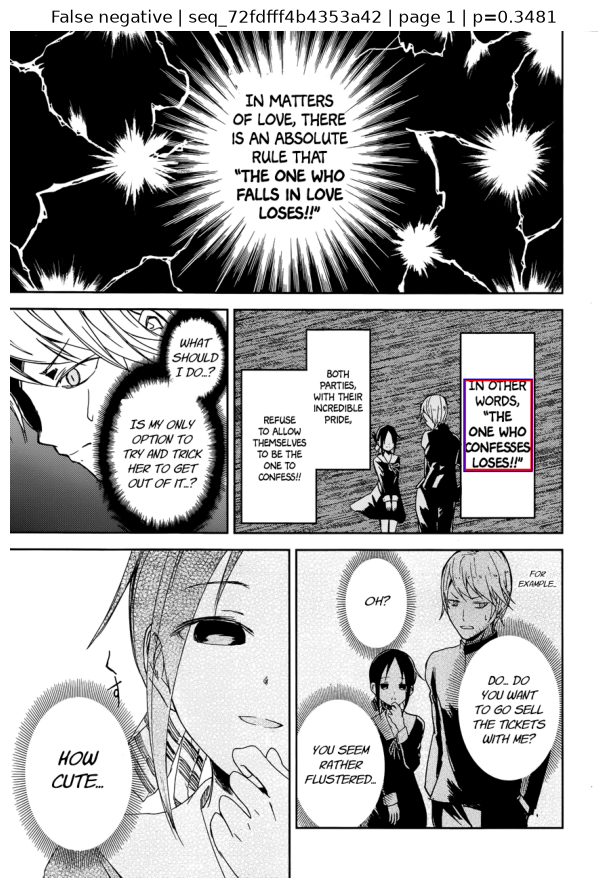

OCR: In other words, "The One who Confesses Loses!!"
GT: IN OTHER WORDS, “THE ONE WHO CONFESSES LOSES!!”
GT speaker: NARRATION
Query: 95 | IoU: 0.9892 | Match: direct | Score: 100.0


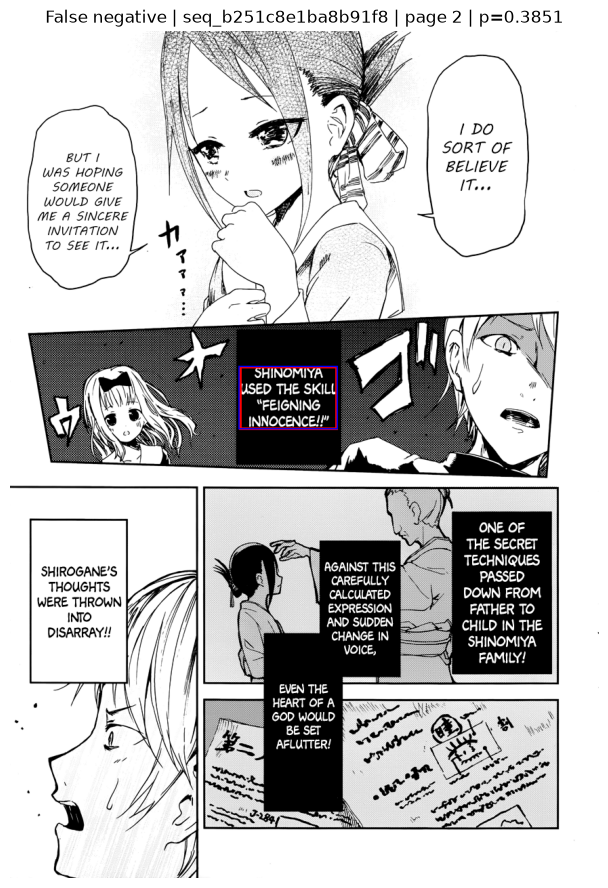

OCR: Shinomiya used the skill "Feishing innocence!"
GT: SHINOMIYA USED THE SKILL “FEIGNING INNOCENCE!!”
GT speaker: NARRATION
Query: 251 | IoU: 0.9832 | Match: direct | Score: 95.35


In [6]:
def show_errors(indices, title):
    print(title, '| Total:', len(indices))
    for index in indices[:MAX_ERRORS]:
        sample = samples[index]
        with Image.open(sample['page_path']) as image:
            page = image.convert('RGB')
        draw = ImageDraw.Draw(page)
        draw.rectangle(sample['bbox'], outline='red', width=4)
        draw.rectangle(sample['detr_bbox'], outline='blue', width=2)
        plt.figure(figsize=(8, 11))
        plt.imshow(page)
        plt.axis('off')
        plt.title(f"{title} | {sample['sequence_id']} | page {sample['page_idx']} | p={probabilities[index]:.4f}")
        plt.show()
        print('OCR:', sample['ocr_text'])
        print('GT:', sample['gt_text'])
        print('GT speaker:', sample['gt_speaker'])
        print('Query:', sample['query_idx'], '| IoU:', round(sample['bbox_iou'], 4),
              '| Match:', sample['match_type'], '| Score:', round(sample['match_score'], 2))


false_positives = np.flatnonzero((labels == 0) & predictions)
false_negatives = np.flatnonzero((labels == 1) & ~predictions)
false_positives = false_positives[np.argsort(-probabilities[false_positives])]
false_negatives = false_negatives[np.argsort(probabilities[false_negatives])]
show_errors(false_positives, 'False positive')
show_errors(false_negatives, 'False negative')


## Reuse tokens during future page inference
The helper below takes text tokens already produced by the existing Magi forward pass.
Retain `query_idx` alongside each text box and reorder boxes, query IDs, and tokens together.
For narration predictions, set the speaker to `NARRATION`; otherwise continue normal association.
This separate experiment does not modify the existing production pipeline.
The F1-selected threshold does not guarantee 90% narration precision.

In [5]:
@torch.no_grad()
def classify_existing_text_tokens(text_tokens):
    features = text_tokens.detach().to(device=DEVICE, dtype=torch.float32)
    assert features.ndim == 2 and features.shape[1] == checkpoint['feature_dim']
    probabilities = torch.sigmoid(head(features)).cpu().numpy().astype(np.float64)
    return probabilities, probabilities >= threshold
